# 06 Test Evaluation and Error Analysis

In [1]:
import json
from pathlib import Path

import joblib
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (accuracy_score, average_precision_score, brier_score_loss, confusion_matrix, f1_score,
                             log_loss, precision_recall_curve, precision_score, recall_score, roc_auc_score, roc_curve)

PROCESSED = Path("../data/processed")
MODELS = Path("../models")
RESULTS = Path("../results")
FIG = RESULTS / "figures"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
COLORS = {"Rule: auto-renew off": "#94A3B8", "Logistic regression": "#B45309", "Random forest": "#7C3AED",
          "LightGBM (default)": "#0EA5E9", "LightGBM (tuned)": "#1D4ED8"}

cfg = json.loads((MODELS / "model_config.json").read_text())
FEATURES, TAU = cfg["features"], cfg["threshold"]
X_test = pd.read_parquet(PROCESSED / "X_test.parquet")
y_test = pd.read_parquet(PROCESSED / "y_test.parquet").is_churn.values
Xt = X_test[FEATURES]
print(f"test rows {len(X_test):,} | churners {y_test.sum():,} | threshold tau = {TAU} (chosen on validation)")

test rows 189,338 | churners 17,029 | threshold tau = 0.45 (chosen on validation)


## Test Metrics

In [2]:
base = joblib.load(MODELS / "baselines.joblib")
champion = lgb.Booster(model_file=str(MODELS / "lgbm_champion.txt"))
probs = {
    "Majority (prior)": base["dummy"].predict_proba(Xt)[:, 1],
    "Rule: auto-renew off": Xt.last_auto_renew.fillna(0).map(base["rule_rates"]).values,
    "Logistic regression": base["logreg"].predict_proba(Xt)[:, 1],
    "Random forest": joblib.load(MODELS / "random_forest.joblib").predict_proba(Xt)[:, 1],
    "LightGBM (default)": lgb.Booster(model_file=str(MODELS / "lgbm_default.txt")).predict(Xt),
    "LightGBM (tuned)": champion.predict(Xt),
}

def metrics(y, p, t=TAU):
    pred = p >= t
    return {"pr_auc": average_precision_score(y, p), "roc_auc": roc_auc_score(y, p),
            "log_loss": log_loss(y, np.clip(p, 1e-6, 1 - 1e-6)), "brier": brier_score_loss(y, p),
            "accuracy": accuracy_score(y, pred), "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred), "f1": f1_score(y, pred)}

test_table = pd.DataFrame({m: metrics(y_test, p) for m, p in probs.items()}).T.round(4)
test_table.to_csv(RESULTS / "test_metrics.csv")
test_table

,pr_auc,roc_auc,log_loss,brier,accuracy,precision,recall,f1
Majority (prior),0.0899,0.5000,0.3024,0.0819,0.9101,0.0000,0.0000,0.0000
Rule: auto-renew off,0.3164,0.7748,0.2286,0.0632,0.8984,0.4528,0.6241,0.5248
Logistic regression,0.8946,0.9767,0.0873,0.0217,0.9728,0.8565,0.8373,0.8468
Random forest,0.9596,0.9946,0.0489,0.0138,0.9808,0.8878,0.9008,0.8942
LightGBM (default),0.9619,0.9953,0.0467,0.0134,0.9809,0.8848,0.9053,0.8950
LightGBM (tuned),0.9644,0.9958,0.0452,0.0131,0.9813,0.8828,0.9129,0.8976


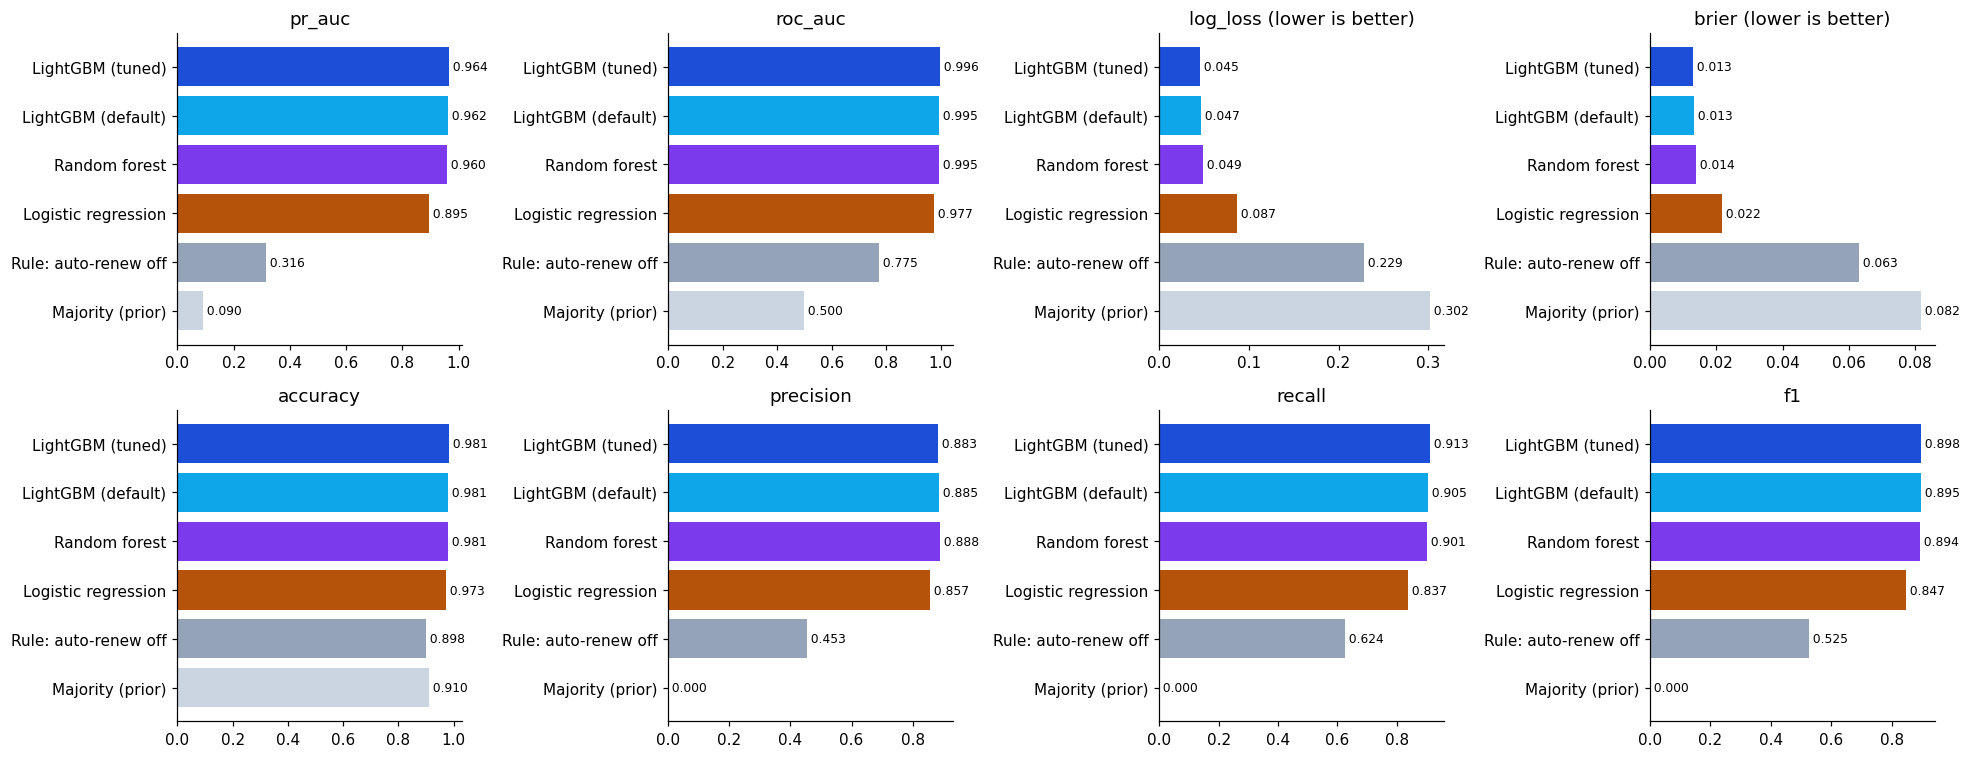

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, col in zip(axes.ravel(), test_table.columns):
    ax.barh(test_table.index, test_table[col], color=[COLORS.get(m, "#CBD5E1") for m in test_table.index])
    ax.set(title=col + (" (lower is better)" if col in ("log_loss", "brier") else ""))
    for i, v in enumerate(test_table[col]):
        ax.text(v, i, f" {v:.3f}", va="center", fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "test_metric_comparison.png"); plt.show()

## Bootstrap Confidence Intervals

In [4]:
rng = np.random.default_rng(0)
p_champ = probs["LightGBM (tuned)"]
boot_idx = [rng.integers(0, len(y_test), len(y_test)) for _ in range(1000)]
boot = pd.DataFrame([{"pr_auc": average_precision_score(y_test[i], p_champ[i]), "roc_auc": roc_auc_score(y_test[i], p_champ[i]),
                      "log_loss": log_loss(y_test[i], p_champ[i]), "f1": f1_score(y_test[i], p_champ[i] >= TAU)} for i in boot_idx])
ci = boot.quantile([0.025, 0.975]).T.round(4)
ci.columns = ["low", "high"]
ci

,low,high
pr_auc,0.9624,0.9664
roc_auc,0.9955,0.9961
log_loss,0.0439,0.0464
f1,0.8942,0.9010


## ROC and Precision Recall Curves

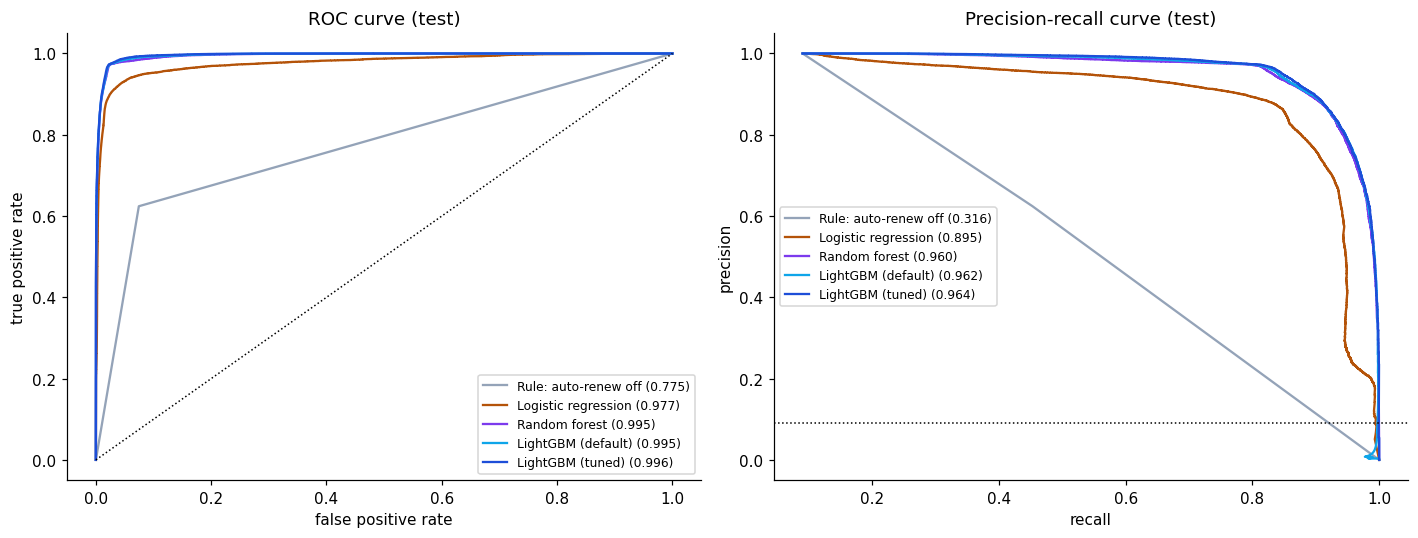

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for name, color in COLORS.items():
    f, t, _ = roc_curve(y_test, probs[name]); ax[0].plot(f, t, color=color, label=f"{name} ({roc_auc_score(y_test, probs[name]):.3f})")
    r, pr, _ = precision_recall_curve(y_test, probs[name]); ax[1].plot(r, pr, color=color, label=f"{name} ({average_precision_score(y_test, probs[name]):.3f})")
ax[0].plot([0, 1], [0, 1], "k:", lw=1); ax[0].set(title="ROC curve (test)", xlabel="false positive rate", ylabel="true positive rate")
ax[1].axhline(y_test.mean(), color="k", ls=":", lw=1); ax[1].set(title="Precision-recall curve (test)", xlabel="recall", ylabel="precision")
ax[0].legend(fontsize=8); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "test_roc_pr.png"); plt.show()

## Confusion Matrix and Threshold Curves

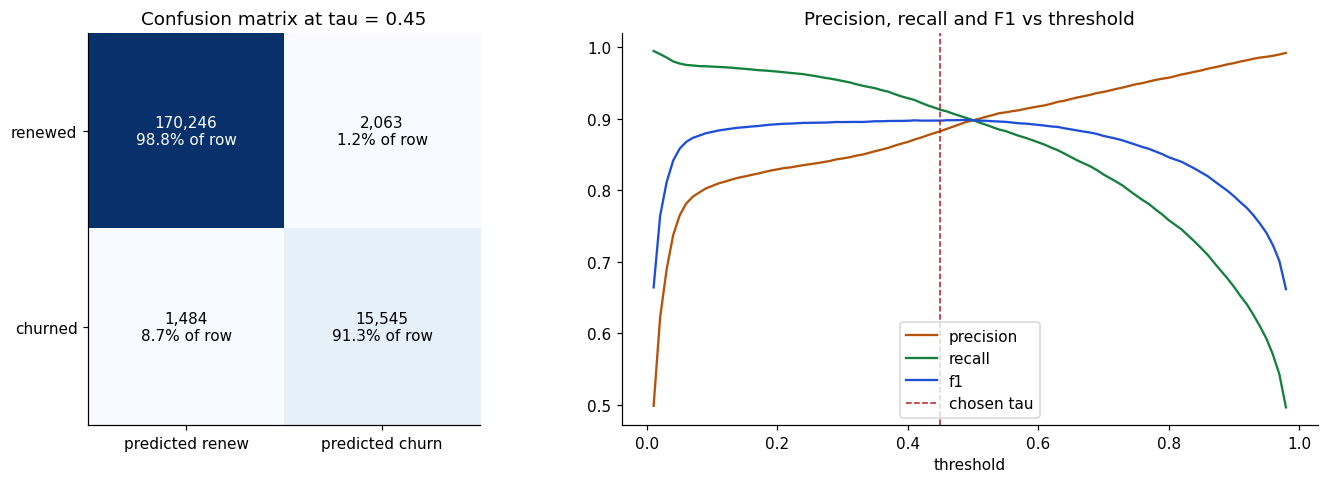

In [6]:
pred = p_champ >= TAU
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
grid = np.round(np.arange(0.01, 0.99, 0.01), 2)
thresholds = []
for t in grid:
    c = confusion_matrix(y_test, p_champ >= t).ravel()
    thresholds.append({"t": float(t), "tn": int(c[0]), "fp": int(c[1]), "fn": int(c[2]), "tp": int(c[3])})
th = pd.DataFrame(thresholds)
th["precision"] = th.tp / (th.tp + th.fp).clip(lower=1)
th["recall"] = th.tp / (th.tp + th.fn)
th["f1"] = 2 * th.precision * th.recall / (th.precision + th.recall)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
cm = np.array([[tn, fp], [fn, tp]])
ax[0].imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    ax[0].text(j, i, f"{v:,}\n{v / cm[i].sum():.1%} of row", ha="center", va="center", color="white" if v > cm.max() / 2 else "black")
ax[0].set(xticks=[0, 1], yticks=[0, 1], xticklabels=["predicted renew", "predicted churn"], yticklabels=["renewed", "churned"],
          title=f"Confusion matrix at tau = {TAU}")
for col, color in [("precision", "#B45309"), ("recall", "#15803D"), ("f1", "#1D4ED8")]:
    ax[1].plot(th.t, th[col], color=color, label=col)
ax[1].axvline(TAU, color="#B91C1C", ls="--", lw=1, label="chosen tau")
ax[1].set(title="Precision, recall and F1 vs threshold", xlabel="threshold"); ax[1].legend()
plt.tight_layout(); plt.savefig(FIG / "test_confusion_threshold.png"); plt.show()

## Calibration Score Distribution and Gains

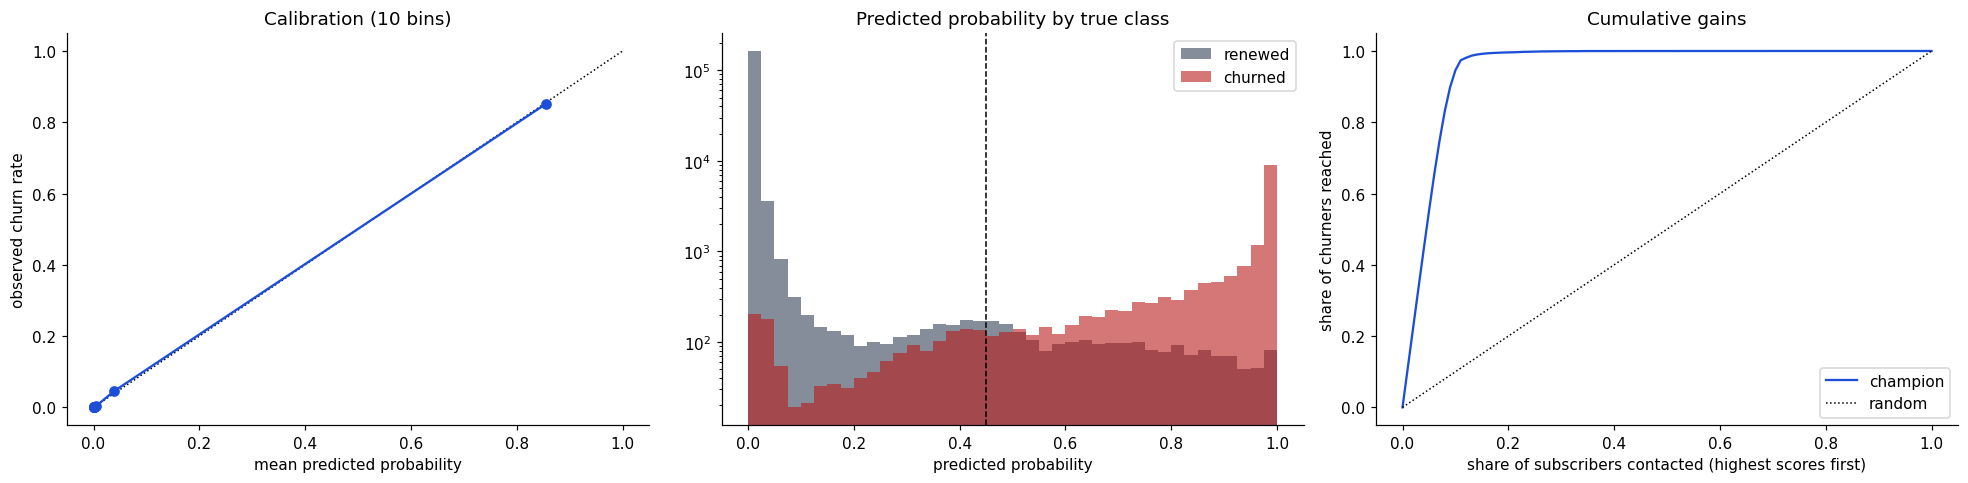

top 10% of scores reach 94.6% of churners


In [7]:
bins = np.quantile(p_champ, np.linspace(0, 1, 11)); bins[0], bins[-1] = 0, 1
cal = (pd.DataFrame({"p": p_champ, "y": y_test, "bin": pd.cut(p_champ, np.unique(bins), include_lowest=True)})
         .groupby("bin", observed=True).agg(mean_pred=("p", "mean"), observed=("y", "mean"), n=("y", "size")).reset_index(drop=True))
edges = np.linspace(0, 1, 41)
score_hist = {"edges": edges.tolist(), "churned": np.histogram(p_champ[y_test == 1], edges)[0].tolist(),
              "renewed": np.histogram(p_champ[y_test == 0], edges)[0].tolist()}
order = np.argsort(-p_champ)
frac = np.linspace(0, 1, 101)
captured = [float(y_test[order[: int(round(f * len(order)))]].sum() / y_test.sum()) for f in frac]
gains = {"contacted": frac.round(2).tolist(), "captured": np.round(captured, 4).tolist()}

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
ax[0].plot([0, 1], [0, 1], "k:", lw=1); ax[0].plot(cal.mean_pred, cal.observed, "o-", color="#1D4ED8")
ax[0].set(title="Calibration (10 bins)", xlabel="mean predicted probability", ylabel="observed churn rate")
ax[1].stairs(score_hist["renewed"], edges, fill=True, alpha=0.6, color="#334155", label="renewed")
ax[1].stairs(score_hist["churned"], edges, fill=True, alpha=0.6, color="#B91C1C", label="churned")
ax[1].axvline(TAU, color="k", ls="--", lw=1); ax[1].set(title="Predicted probability by true class", yscale="log", xlabel="predicted probability"); ax[1].legend()
ax[2].plot(frac, captured, color="#1D4ED8", label="champion"); ax[2].plot([0, 1], [0, 1], "k:", lw=1, label="random")
ax[2].set(title="Cumulative gains", xlabel="share of subscribers contacted (highest scores first)", ylabel="share of churners reached"); ax[2].legend()
plt.tight_layout(); plt.savefig(FIG / "test_calibration_gains.png"); plt.show()
print(f"top 10% of scores reach {captured[10]:.1%} of churners")

## Ablation on Test

In [8]:
ab_probs = {name: lgb.Booster(model_file=str(MODELS / f"lgbm_ablation_{name.split()[0].lower()}.txt")).predict(X_test[cols])
            for name, cols in cfg["ablation_sets"].items()}
ab_rows = []
for name, p in ab_probs.items():
    m = metrics(y_test, p)
    pr = [average_precision_score(y_test[i], p[i]) for i in boot_idx[:500]]
    ab_rows.append({"set": name, "n_features": len(cfg["ablation_sets"][name]), **{k: m[k] for k in ["pr_auc", "roc_auc", "log_loss", "f1"]},
                    "pr_auc_low": np.quantile(pr, 0.025), "pr_auc_high": np.quantile(pr, 0.975)})
ablation = pd.DataFrame(ab_rows).round(4)
diff = np.array([average_precision_score(y_test[i], ab_probs["All features"][i]) -
                 average_precision_score(y_test[i], ab_probs["Billing + demographics"][i]) for i in boot_idx[:500]])
ablation_diff = {"mean": float(diff.mean()), "low": float(np.quantile(diff, 0.025)), "high": float(np.quantile(diff, 0.975)),
                 "share_leq_0": float((diff <= 0).mean())}
print(ablation.to_string(index=False))
print(f"PR-AUC gain from adding listening: {ablation_diff['mean']:+.4f} (95% CI {ablation_diff['low']:+.4f} to {ablation_diff['high']:+.4f})")

                     set  n_features  pr_auc  roc_auc  log_loss     f1  pr_auc_low  pr_auc_high
  Billing + demographics          21  0.9562   0.9952    0.0481 0.8948      0.9540       0.9583
Listening + demographics          18  0.3967   0.8017    0.2403 0.3177      0.3880       0.4042
            All features          33  0.9644   0.9958    0.0452 0.8976      0.9624       0.9662
PR-AUC gain from adding listening: +0.0083 (95% CI +0.0073 to +0.0093)


## Errors by Segment

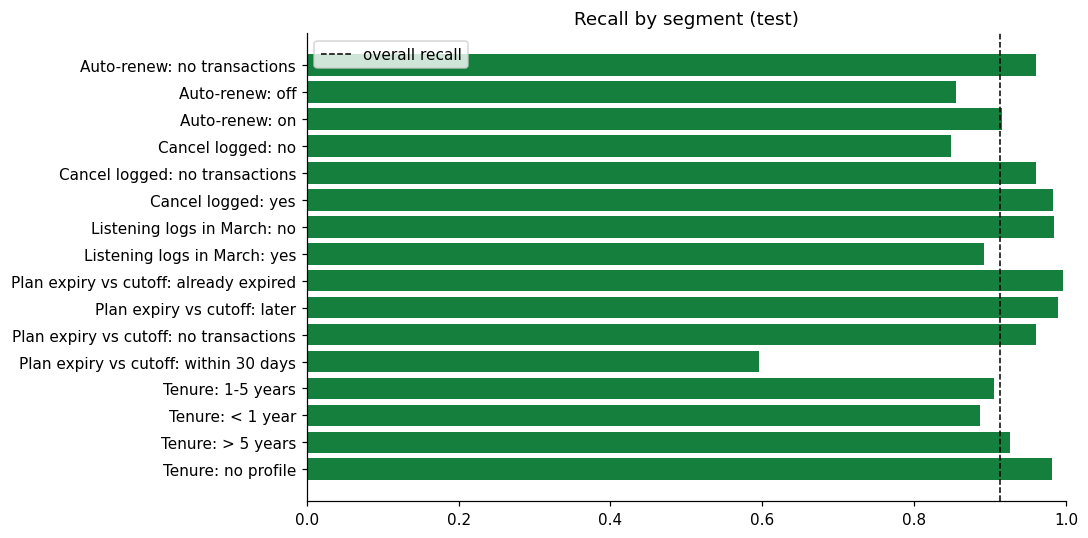

,segment,group,n,churn_rate,recall,precision,fn,fp
0,Auto-renew,no transactions,7248,0.780,0.960,0.815,224,1233
1,Auto-renew,off,16223,0.306,0.856,0.885,717,555
2,Auto-renew,on,165867,0.039,0.915,0.955,543,275
3,Cancel logged,no,178252,0.044,0.848,0.914,1200,632
4,Cancel logged,no transactions,7248,0.780,0.960,0.815,224,1233
5,Cancel logged,yes,3838,0.906,0.983,0.945,60,198
6,Listening logs in March,no,42078,0.090,0.985,0.986,58,52
7,Listening logs in March,yes,147260,0.090,0.892,0.854,1426,2011
8,Plan expiry vs cutoff,already expired,3065,0.954,0.996,0.956,12,134
9,Plan expiry vs cutoff,later,20575,0.268,0.989,0.981,61,107


In [9]:
T = X_test.assign(y=y_test, p=p_champ, pred=pred.astype(int))
segments = {
    "Auto-renew": T.last_auto_renew.map({1.0: "on", 0.0: "off"}).fillna("no transactions"),
    "Cancel logged": T.last_is_cancel.map({1.0: "yes", 0.0: "no"}).fillna("no transactions"),
    "Listening logs in March": T.has_logs.map({1.0: "yes", 0.0: "no"}),
    "Plan expiry vs cutoff": pd.cut(T.days_until_expiration, [-np.inf, -1, 30, np.inf], labels=["already expired", "within 30 days", "later"]).astype(str).replace("nan", "no transactions"),
    "Tenure": pd.cut(T.tenure_days, [-np.inf, 365, 1825, np.inf], labels=["< 1 year", "1-5 years", "> 5 years"]).astype(str).replace("nan", "no profile"),
}
seg_rows = []
for seg, key in segments.items():
    for grp, d in T.groupby(key.values):
        seg_rows.append({"segment": seg, "group": grp, "n": len(d), "churn_rate": d.y.mean(),
                         "recall": recall_score(d.y, d.pred, zero_division=0), "precision": precision_score(d.y, d.pred, zero_division=0),
                         "fn": int(((d.y == 1) & (d.pred == 0)).sum()), "fp": int(((d.y == 0) & (d.pred == 1)).sum())})
seg_table = pd.DataFrame(seg_rows)

fig, ax = plt.subplots(figsize=(10, 5))
lab = seg_table.segment + ": " + seg_table.group
ax.barh(lab[::-1], seg_table.recall[::-1], color="#15803D")
ax.axvline(recall_score(y_test, pred), color="k", ls="--", lw=1, label="overall recall")
ax.set(title="Recall by segment (test)", xlim=(0, 1)); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "test_segment_recall.png"); plt.show()
seg_table.round(3)

## Missed vs Caught Churners

In [10]:
KEY = ["last_auto_renew", "last_is_cancel", "days_until_expiration", "last_plan_days", "tx_count",
       "active_days", "total_hours", "days_since_last_active", "last7_share", "tenure_days"]
outcome = np.select([(T.y == 1) & (T.pred == 1), (T.y == 1) & (T.pred == 0), (T.y == 0) & (T.pred == 1)], ["TP", "FN", "FP"], "TN")
profile = T.assign(outcome=outcome).groupby("outcome")[KEY].median().T[["TP", "FN", "FP", "TN"]].round(2)
fn_auto = float(((T.y == 1) & (T.pred == 0) & (T.last_auto_renew == 1)).sum() / max(fn, 1))
print(f"{fn_auto:.0%} of missed churners still had auto-renew on")
profile

37% of missed churners still had auto-renew on


outcome,TP,FN,FP,TN
last_auto_renew,1.00,0.000000,0.00,1.00
last_is_cancel,0.00,0.000000,0.00,0.00
days_until_expiration,43.50,14.000000,12.00,18.00
last_plan_days,30.00,30.000000,30.00,30.00
tx_count,1.00,1.000000,0.00,1.00
active_days,9.00,24.000000,16.00,14.00
total_hours,8.93,33.700001,18.10,14.11
days_since_last_active,9.00,0.000000,4.00,1.00
last7_share,0.00,0.200000,0.06,0.16
tenure_days,1114.00,880.000000,869.00,1030.00


## Representative Errors

In [11]:
SHOW = ["last_auto_renew", "last_is_cancel", "days_until_expiration", "last_plan_days", "active_days", "days_since_last_active", "total_hours"]

def pick(mask, kind):
    d = T[mask].sort_values("p")
    rows = [d.iloc[int(q * (len(d) - 1))] for q in (0.25, 0.5, 0.75)]  # 25th, 50th, 75th percentile of score
    return [{"kind": kind, "p": float(r.p), **{k: (None if pd.isna(r[k]) else float(r[k])) for k in SHOW}} for r in rows]

examples = pick((T.y == 1) & (T.pred == 0), "missed churner") + pick((T.y == 0) & (T.pred == 1), "false alarm")
pd.DataFrame(examples).round(3)

,kind,p,last_auto_renew,last_is_cancel,days_until_expiration,last_plan_days,active_days,days_since_last_active,total_hours
0,missed churner,0.046,1.0,0.0,0.0,30.0,6.0,0.0,3.906
1,missed churner,0.280,0.0,0.0,7.0,30.0,26.0,1.0,59.277
2,missed churner,0.380,NaN,NaN,NaN,NaN,28.0,2.0,38.482
3,false alarm,0.535,NaN,NaN,NaN,NaN,8.0,1.0,3.143
4,false alarm,0.674,NaN,NaN,NaN,NaN,21.0,9.0,48.254
5,false alarm,0.814,NaN,NaN,NaN,NaN,3.0,20.0,4.509


## Feature Importance

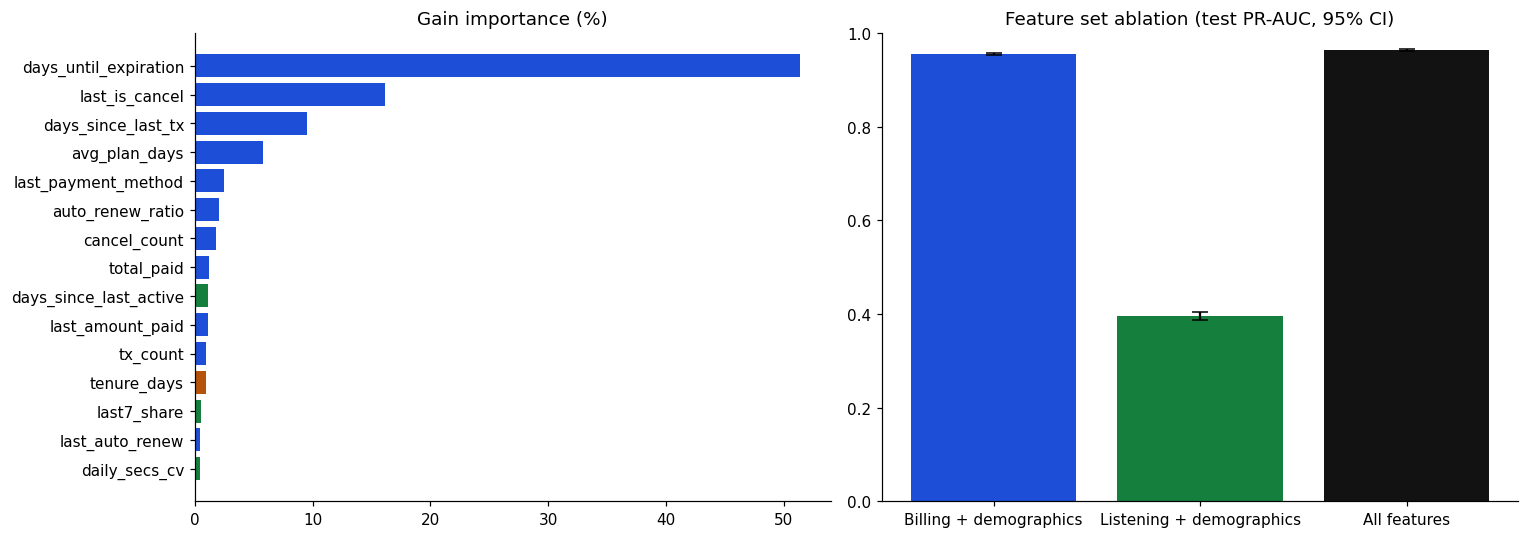

group
billing        93.4
demographic     1.7
listening       4.8
Name: gain_pct, dtype: float64


In [12]:
gain = pd.Series(champion.feature_importance("gain"), index=champion.feature_name())
contrib = champion.predict(Xt.sample(20_000, random_state=0), pred_contrib=True)[:, :-1]
imp = pd.DataFrame({"gain_pct": gain / gain.sum() * 100, "mean_abs_contrib": np.abs(contrib).mean(0)}, index=champion.feature_name())
imp["group"] = imp.index.map({f: g for g, fs in cfg["groups"].items() for f in fs})
imp = imp.sort_values("gain_pct", ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
top = imp.head(15)[::-1]
ax[0].barh(top.index, top.gain_pct, color=top.group.map({"billing": "#1D4ED8", "listening": "#15803D", "demographic": "#B45309"}))
ax[0].set(title="Gain importance (%)")
ax[1].bar(ablation.set, ablation.pr_auc, yerr=[ablation.pr_auc - ablation.pr_auc_low, ablation.pr_auc_high - ablation.pr_auc],
          color=["#1D4ED8", "#15803D", "#121212"], capsize=5)
ax[1].set(title="Feature set ablation (test PR-AUC, 95% CI)", ylim=(0, 1))
plt.tight_layout(); plt.savefig(FIG / "test_importance_ablation.png"); plt.show()
print(imp.groupby("group").gain_pct.sum().round(1))

In [13]:
def curve_points(y, p, n=120):
    f, t, _ = roc_curve(y, p)
    r, pr, _ = precision_recall_curve(y, p)
    ri = np.unique(np.linspace(0, len(f) - 1, n).astype(int)); pi = np.unique(np.linspace(0, len(r) - 1, n).astype(int))
    return {"roc": np.round(np.c_[f[ri], t[ri]], 4).tolist(), "pr": np.round(np.c_[r[pi], pr[pi]], 4).tolist()}

evaluation = {
    "test_metrics": test_table.reset_index(names="model").to_dict(orient="records"),
    "champion": {"threshold": TAU, "ci": ci.to_dict(orient="index"), "confusion": {"tp": int(tp), "fp": int(fp), "fn": int(fn), "tn": int(tn)},
                 "n_test": int(len(y_test)), "params": cfg["best_params"], "n_trees": cfg["n_trees"], "fn_auto_renew_on": fn_auto},
    "curves": {m: curve_points(y_test, p) for m, p in probs.items() if m != "Majority (prior)"},
    "thresholds": thresholds, "calibration": cal.round(4).to_dict(orient="records"),
    "score_hist": score_hist, "gains": gains,
    "ablation": ablation.to_dict(orient="records"), "ablation_diff": ablation_diff,
    "segments": seg_table.round(4).to_dict(orient="records"),
    "error_profile": profile.reset_index(names="feature").to_dict(orient="records"),
    "examples": examples,
    "importance": imp.head(15).round(4).reset_index(names="feature").to_dict(orient="records"),
    "importance_by_group": imp.groupby("group").gain_pct.sum().round(2).to_dict(),
}
(RESULTS / "evaluation.json").write_text(json.dumps(evaluation, default=float))
print("saved results/evaluation.json and results/test_metrics.csv")

saved results/evaluation.json and results/test_metrics.csv
